# 1D free particle: sampled wavepacket evolution

Moving, spreading Gaussian on a periodic grid; V(x)=0. Units: $m=\hbar=1$.

## Direct Qiskit construction

No repository helper functions are imported. This notebook explicitly prepares the sampled Gaussian, applies diagonal potential and kinetic phases around QFT/QFT†, obtains ideal probabilities from the unmeasured Qiskit circuit, then samples that same circuit with Aer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister, transpile
from qiskit.circuit.library import DiagonalGate, QFTGate
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

def periodic_grid(num_qubits, length):
    """N=2**n endpoint-excluded position samples."""
    return np.linspace(-length / 2, length / 2, 2**num_qubits, endpoint=False)

def gaussian_packet(x, x0, sigma, k0):
    """Normalized sampled Gaussian; sigma is its probability-density standard deviation."""
    psi = np.exp(-(x - x0)**2 / (4 * sigma**2)) * np.exp(1j * k0 * x)
    return psi / np.linalg.norm(psi)

def wavenumbers(x):
    return 2 * np.pi * np.fft.fftfreq(len(x), d=x[1] - x[0])

def split_step_circuit(psi, x, potential, dt, steps):
    """Qiskit circuit: prepare psi, then V(dt/2), QFT, T(dt), QFT†, V(dt/2)."""
    n = int(np.log2(len(psi)))
    position = QuantumRegister(n, "x")
    circuit = QuantumCircuit(position, name="split_step")
    circuit.initialize(psi, position)
    potential_phase = np.exp(-.5j * potential * dt)
    kinetic_phase = np.exp(-.5j * wavenumbers(x)**2 * dt)
    for _ in range(steps):
        circuit.append(DiagonalGate(potential_phase), position)
        circuit.append(QFTGate(n), position)
        circuit.append(DiagonalGate(kinetic_phase), position)
        circuit.append(QFTGate(n).inverse(), position)
        circuit.append(DiagonalGate(potential_phase), position)
    return circuit, position

def snapshot(psi, x, potential, dt, steps, shots=16384, seed=20261023):
    """Same unmeasured circuit for Statevector and sampled Aer measurements."""
    circuit, position = split_step_circuit(psi, x, potential, dt, steps)
    ideal = np.abs(Statevector.from_instruction(circuit).data)**2
    measured = circuit.copy()
    classical = ClassicalRegister(len(position), "position")
    measured.add_register(classical)
    measured.measure(position, classical)
    backend = AerSimulator(seed_simulator=seed + steps)
    compiled = transpile(measured, backend, optimization_level=0, seed_transpiler=seed)
    raw = backend.run(compiled, shots=shots).result().get_counts()
    counts = np.array([raw.get(format(j, f"0{len(position)}b"), 0) for j in range(2**len(position))])
    observed = counts / shots
    max_error = float(np.max(np.abs(observed - ideal)))
    four_sigma = float(4 * np.sqrt(np.max(ideal * (1 - ideal)) / shots))
    return dict(steps=steps, circuit=circuit, ideal=ideal, counts=counts, observed=observed, max_error=max_error, four_sigma=four_sigma)

In [2]:
# Six qubits = 64 physical-position bins. Set n=5 for a faster 32-bin run.
n, length, dt, shots = 6, 16.0, 0.04, 16384
snapshot_times = (0, 0.5, 1, 1.5, 2, 2.5)
snapshot_steps = [round(time / dt) for time in snapshot_times]
x = periodic_grid(n, length)
potential = np.zeros_like(x)
psi0 = gaussian_packet(x, x0=-4.0, sigma=0.7, k0=1.5)
print("snapshot steps:", snapshot_steps)
print("initial norm:", np.sum(np.abs(psi0)**2))

snapshot steps: [0, 12, 25, 38, 50, 62]
initial norm: 1.0


## Measurement/order check

The basis state |j⟩ maps to position x[j]. The two checks below first measure the initialization circuit (iteration zero), then the same circuit after a short evolution. The diagnostic compares the maximum measured-versus-ideal probability difference with a conservative four-standard-deviation binomial sampling scale.

In [3]:
# Debugging sequence: initialization first, then a short coherent evolution.
snapshots = {}
for steps in (snapshot_steps[0], snapshot_steps[1]):
    snapshots[steps] = snapshot(psi0, x, potential, dt, steps, shots)
    result = snapshots[steps]
    print(f"step={steps:3d}, t={steps * dt:.2f}: max |Pmeasured-Pideal|={result['max_error']:.4f}; 4σ bound={result['four_sigma']:.4f}")
assert np.isclose(snapshots[0]["counts"].sum(), shots)

step=  0, t=0.00: max |Pmeasured-Pideal|=0.0050; 4σ bound=0.0109
step= 12, t=0.48: max |Pmeasured-Pideal|=0.0056; 4σ bound=0.0104


## Circuit preparation

The map is compact for readability. The exact circuit used for every result is constructed by split_step_circuit; each repeated block is a symmetric Strang step.

In [4]:
# Compact map. one_step retains the corresponding exact parameterized Qiskit circuit.
from qiskit.circuit import Gate
one_step, _ = split_step_circuit(psi0, x, potential, dt, steps=1)
circuit_map = QuantumCircuit(n)
for label in ("Initialize ψ₀", "V(Δt/2)", "QFT", "T(Δt)", "QFT†", "V(Δt/2)"):
    circuit_map.append(Gate(label, n, []), range(n))
print(circuit_map.draw("text", fold=140))
print("Exact one-step operations:", one_step.count_ops())

     ┌────────────────┐┌──────────┐┌──────┐┌────────┐┌───────┐┌──────────┐
q_0: ┤0               ├┤0         ├┤0     ├┤0       ├┤0      ├┤0         ├
     │                ││          ││      ││        ││       ││          │
q_1: ┤1               ├┤1         ├┤1     ├┤1       ├┤1      ├┤1         ├
     │                ││          ││      ││        ││       ││          │
q_2: ┤2               ├┤2         ├┤2     ├┤2       ├┤2      ├┤2         ├
     │  Initialize ψ₀ ││  V(Δt/2) ││  QFT ││  T(Δt) ││  QFT† ││  V(Δt/2) │
q_3: ┤3               ├┤3         ├┤3     ├┤3       ├┤3      ├┤3         ├
     │                ││          ││      ││        ││       ││          │
q_4: ┤4               ├┤4         ├┤4     ├┤4       ├┤4      ├┤4         ├
     │                ││          ││      ││        ││       ││          │
q_5: ┤5               ├┤5         ├┤5     ├┤5       ├┤5      ├┤5         ├
     └────────────────┘└──────────┘└──────┘└────────┘└───────┘└──────────┘
Exact one-step operations

## Six sampled evolution snapshots

Bars: Aer counts divided by shots. Black line: probabilities from the identical unmeasured Qiskit circuit. Red dashed curve: free potential V(x)=0, on its own right-side energy axis.

No barrier or scattering interpretation.

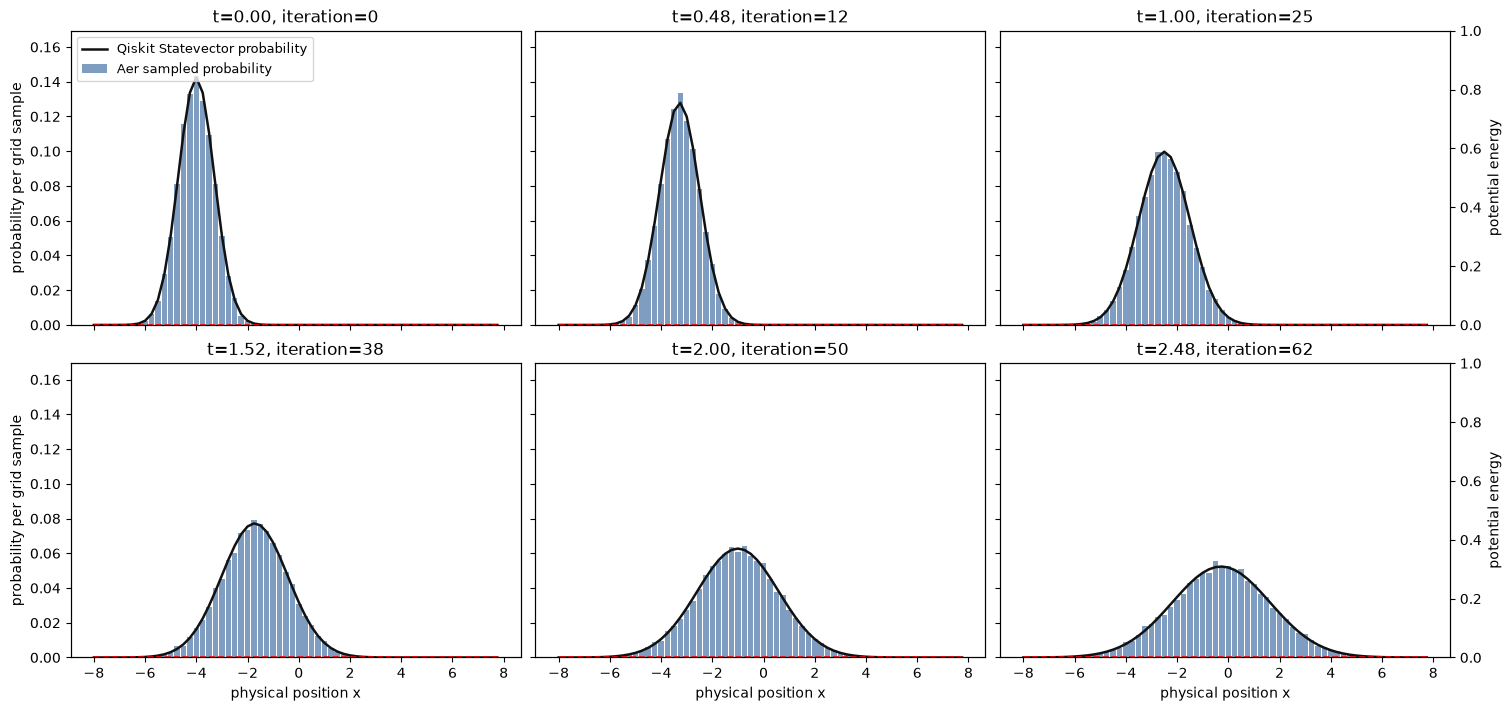

Snapshot diagnostics
t=0.00, iteration=  0: max error=0.0050, 4σ bound=0.0109
t=0.50, iteration= 12: max error=0.0056, 4σ bound=0.0104
t=1.00, iteration= 25: max error=0.0031, 4σ bound=0.0094
t=1.50, iteration= 38: max error=0.0040, 4σ bound=0.0083
t=2.00, iteration= 50: max error=0.0031, 4σ bound=0.0076
t=2.50, iteration= 62: max error=0.0033, 4σ bound=0.0070


In [5]:
# Reuse audited results; generate missing snapshots with actual Aer shot sampling.
for steps in snapshot_steps:
    if steps not in snapshots:
        snapshots[steps] = snapshot(psi0, x, potential, dt, steps, shots)

probability_max = max(result["observed"].max() for result in snapshots.values()) * 1.18
probability_max = max(probability_max, .02)
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True, constrained_layout=True)
dx = x[1] - x[0]
for axis, time, steps in zip(axes.flat, snapshot_times, snapshot_steps):
    result = snapshots[steps]
    axis.bar(x, result["observed"], width=.86 * dx, color="#4C78A8", alpha=.72, label="Aer sampled probability")
    axis.plot(x, result["ideal"], color="#111111", lw=1.8, label="Qiskit Statevector probability")
    axis.set(title=f"t={steps * dt:.2f}, iteration={steps}", ylim=(0, probability_max))
    potential_axis = axis.twinx()
    potential_axis.plot(x, potential, "r--", lw=1.2)
    potential_axis.set_ylim(0, max(1.0, potential.max() * 1.15))
    if axis in axes[:, -1]:
        potential_axis.set_ylabel("potential energy")
    else:
        potential_axis.set_yticks([])
axes[0, 0].set_ylabel("probability per grid sample")
axes[1, 0].set_ylabel("probability per grid sample")
for axis in axes[1]:
    axis.set_xlabel("physical position x")
axes[0, 0].legend(loc="upper left", fontsize=9)
plt.show()

print("Snapshot diagnostics")
for time, steps in zip(snapshot_times, snapshot_steps):
    result = snapshots[steps]
    print(f"t={time:4.2f}, iteration={steps:3d}: max error={result['max_error']:.4f}, 4σ bound={result['four_sigma']:.4f}")

## Limits

Ideal local Aer simulation only: no hardware calibration noise, routing, or imperfect preparation. The periodic grid eventually wraps a packet across the domain boundary; these snapshot windows were selected to avoid that artifact.